<a href="https://colab.research.google.com/github/ishuu9837/BAGGING-CONCEPT/blob/main/Image_Colourisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Importing a bunch of libraries to build a deep learning project for image colorization

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from skimage.color import rgb2lab, lab2rgb
from skimage.transform import resize
import os
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv2D, Conv2DTranspose, BatchNormalization, LeakyReLU, ReLU, Concatenate
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping



*   
*   fetch_lfw_people → Loads the Labeled Faces in the Wild dataset (face images)
*   train_test_split → Splits data into training and testing sets
*   rgb2lab → Converts RGB image → LAB color space   
*   lab2rgb → Converts LAB → RGB
*   resize → Resize images to fixed dimensions   
*    tf- Main deep learning framework used to build and train neural networks.
*    keras.models- Used to define the neural network architecture.
*    import Adam-Adam optimizer updates weights during training
*     EarlyStopping- Stops training when model stops improving











In [ ]:
from google.colab import files

In [ ]:
print("/content/sample_data/lfw_readme.csv")
uploaded = files.upload()

/content/sample_data/lfw_readme.csv


Saving lfw_readme.csv to lfw_readme.csv


Loop through uploads — iterates over each file the user uploaded

Validate file type — checks if the file ends with .tgz or .tar.gz, skips it if not

Extract the archive — opens and extracts the valid tar file into the current directory

Handle errors — if the file is corrupted or invalid, catches the error and prints a clean message

Confirm completion — prints "Done" after all files have been processed

In [ ]:
lfw = fetch_lfw_people(color=True, min_faces_per_person=10)
images = lfw.images


IMG_SIZE = 64
print("Resizing and converting to Lab color space...")
images_resized = np.array([resize(img, (IMG_SIZE, IMG_SIZE)) for img in images])

lab_images = np.array([rgb2lab(img) for img in images_resized])


L_channels = lab_images[:, :, :, 0:1]
ab_channels = lab_images[:, :, :, 1:]

L_norm = (L_channels / 50.0) - 1.0

ab_norm = ab_channels / 128.0

X_train, X_val, y_train, y_val = train_test_split(L_norm, ab_norm, test_size=0.15, random_state=42)
print(f"Training shapes - X: {X_train.shape}, y: {y_train.shape}")

Resizing and converting to Lab color space...
Training shapes - X: (3675, 64, 64, 1), y: (3675, 64, 64, 2)


The dataset is loaded using fetch_lfw_people, which provides face images for training.

All images are resized to 64×64 so the neural network can process them uniformly.

Images are converted from RGB to Lab color space to separate brightness (L) from color (ab).

The L channel (grayscale) is used as input, while ab channels (color) are used as output labels.

Both L and ab values are normalized to the range [-1, 1] to make training faster and more stable.

In [ ]:

def build_unet(input_shape=(IMG_SIZE, IMG_SIZE, 1)):
    inputs = Input(shape=input_shape)


    def encoder_block(x, filters):
        x = Conv2D(filters, kernel_size=4, strides=2, padding='same')(x)
        x = BatchNormalization()(x)
        x = LeakyReLU(0.2)(x)
        return x

    e1 = encoder_block(inputs, 64)
    e2 = encoder_block(e1, 128)
    e3 = encoder_block(e2, 256)
    e4 = encoder_block(e3, 512)


    b = Conv2D(512, kernel_size=3, strides=1, padding='same')(e4)
    b = ReLU()(b)

    def decoder_block(x, skip, filters):
        x = Conv2DTranspose(filters, kernel_size=4, strides=2, padding='same')(x)
        x = Concatenate()([x, skip])
        x = ReLU()(x)
        return x

    d1 = decoder_block(b, e3, 512)
    d2 = decoder_block(d1, e2, 256)
    d3 = decoder_block(d2, e1, 128)
    d4 = decoder_block(d3, inputs, 64)


    outputs = Conv2DTranspose(2, kernel_size=4, strides=1, padding='same', activation='tanh')(d4)

    return Model(inputs, outputs, name="Colorization_UNet")

model = build_unet()
model.compile(optimizer=Adam(learning_rate=2e-4), loss='mae')



A U-Net model is defined where the input is a grayscale image (L channel).

The encoder uses Conv2D layers to downsample the image and extract features.

The bottleneck processes the compressed features at the smallest size.

The decoder uses Conv2DTranspose to upsample and combines features using skip connections (Concatenate) from the encoder.

The final layer outputs 2 channels (ab colors) with tanh, and the model is compiled using Adam optimizer and MAE loss.

Epoch 1/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 59s 1s/step - loss: 0.0756 - val_loss: 0.0954
Epoch 2/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 7s 216ms/step - loss: 0.0538 - val_loss: 0.0749
Epoch 3/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 7s 223ms/step - loss: 0.0508 - val_loss: 0.0646
Epoch 4/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 7s 224ms/step - loss: 0.0485 - val_loss: 0.0532
Epoch 5/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 7s 224ms/step - loss: 0.0484 - val_loss: 0.0528
Epoch 6/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 7s 228ms/step - loss: 0.0467 - val_loss: 0.0523
Epoch 7/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 7s 233ms/step - loss: 0.0451 - val_loss: 0.0517
Epoch 8/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 7s 239ms/step - loss: 0.0437 - val_loss: 0.0564
Epoch 9/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 8s 245ms/step - loss: 0.0432 - val_loss: 0.0517
Epoch 10/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 8s 247ms/step - loss: 0.0408 - val_loss: 0.0554


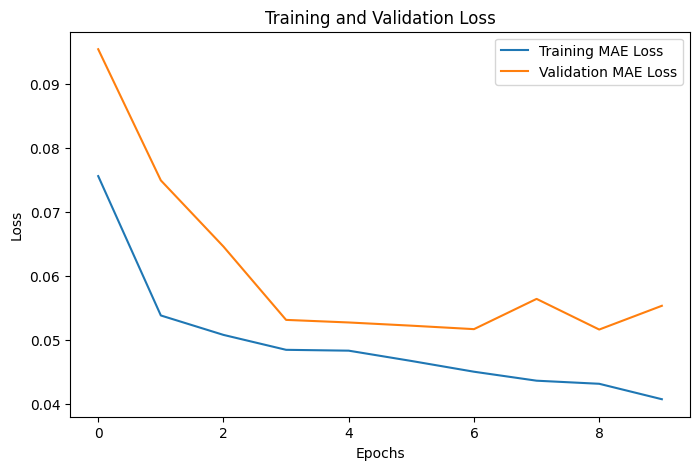

In [ ]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=120
)

plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training MAE Loss')
plt.plot(history.history['val_loss'], label='Validation MAE Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

Evaluating on Validation Data...
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


/tmp/ipykernel_5016/437345088.py:21: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 2 negative Z values that have been clipped to zero
  rgb_pred = np.clip(lab2rgb(lab_pred), 0, 1)
/tmp/ipykernel_5016/437345088.py:21: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 3 negative Z values that have been clipped to zero
  rgb_pred = np.clip(lab2rgb(lab_pred), 0, 1)


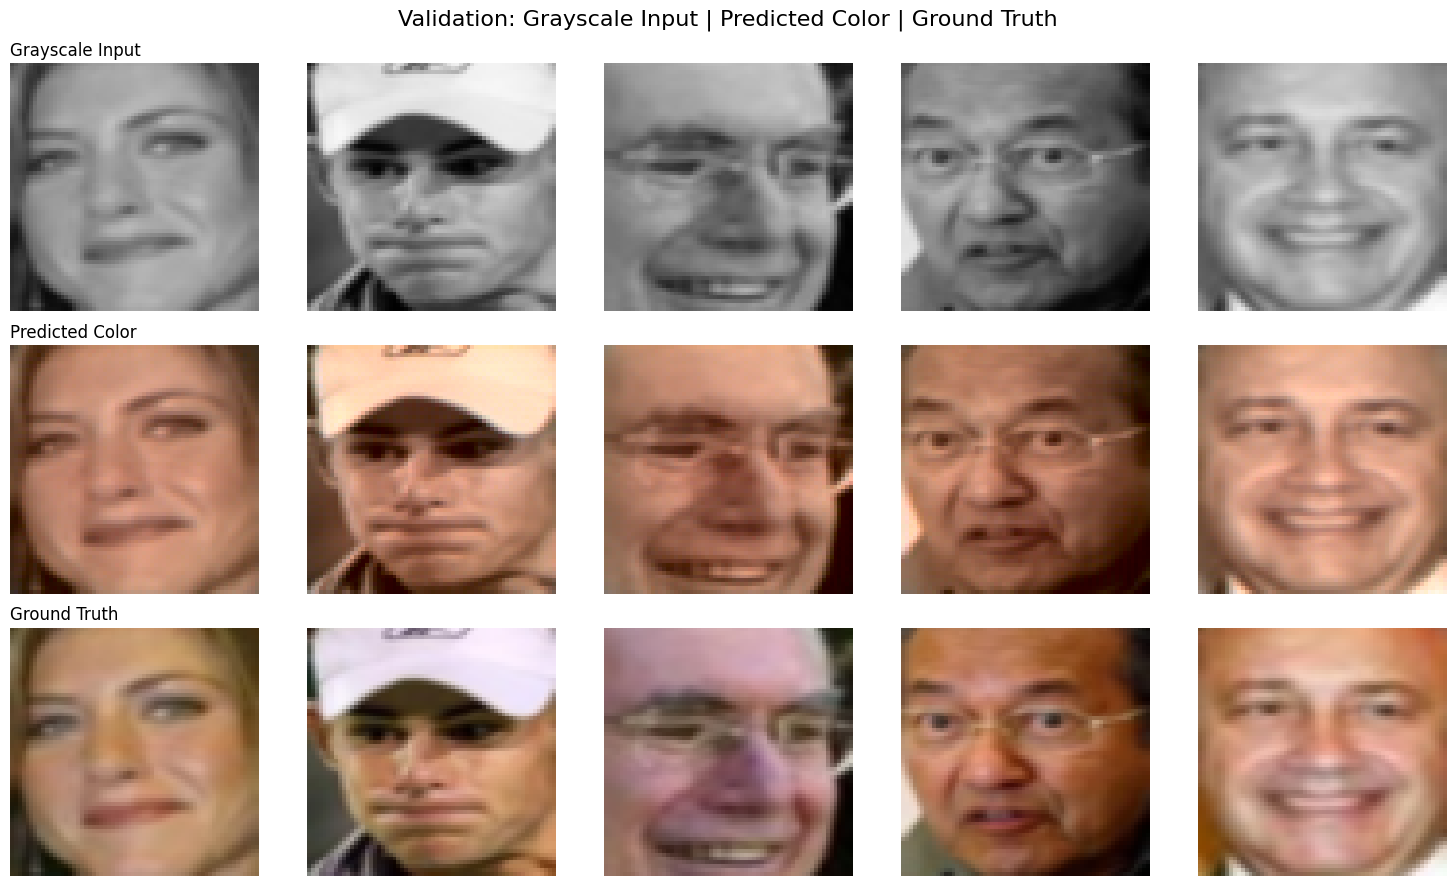

In [ ]:

def plot_results(L_val, ab_true, model, num_images=5):

    ab_pred = model.predict(L_val[:num_images])

    fig, axes = plt.subplots(3, num_images, figsize=(15, 9))
    fig.suptitle("Validation: Grayscale Input | Predicted Color | Ground Truth", fontsize=16)

    for i in range(num_images):

        L_denorm = (L_val[i] + 1.0) * 50.0


        ab_pred_denorm = ab_pred[i] * 128.0
        ab_true_denorm = ab_true[i] * 128.0


        lab_pred = np.concatenate((L_denorm, ab_pred_denorm), axis=-1)
        lab_true = np.concatenate((L_denorm, ab_true_denorm), axis=-1)


        rgb_pred = np.clip(lab2rgb(lab_pred), 0, 1)
        rgb_true = np.clip(lab2rgb(lab_true), 0, 1)


        gray_display = L_denorm / 100.0
        gray_display = np.concatenate([gray_display]*3, axis=-1)


        axes[0, i].imshow(gray_display)
        axes[0, i].axis('off')
        if i == 0: axes[0, i].set_title("Grayscale Input", loc='left')


        axes[1, i].imshow(rgb_pred)
        axes[1, i].axis('off')
        if i == 0: axes[1, i].set_title("Predicted Color", loc='left')


        axes[2, i].imshow(rgb_true)
        axes[2, i].axis('off')
        if i == 0: axes[2, i].set_title("Ground Truth", loc='left')

    plt.tight_layout()
    plt.show()

print("Evaluating on Validation Data...")
plot_results(X_val, y_val, model)


The function predicts color (ab channels) from grayscale validation images using the trained model.

It denormalizes L and ab values to convert them back to original ranges.

Reconstructs images by combining L + predicted/true ab and converts them to RGB.

Creates a 3-row plot: grayscale input, predicted color, and actual (ground truth) color.

Finally, it displays the comparison to evaluate model performance visually.


Upload a portrait photo to test the colorization:


Saving hero.jpg to hero.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


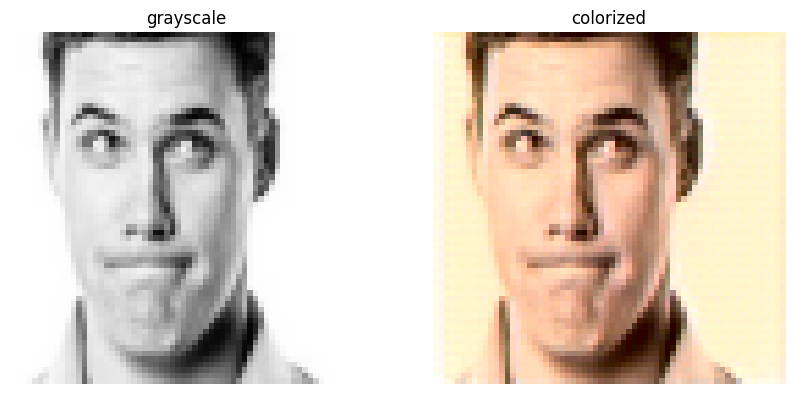

In [ ]:

from google.colab import files
from tensorflow.keras.preprocessing.image import load_img, img_to_array

print("\nUpload a portrait photo to test the colorization:")
uploaded = files.upload()

for filename in uploaded.keys():

    img = load_img(filename)
    img_array = img_to_array(img) / 255.0
    img_resized = resize(img_array, (IMG_SIZE, IMG_SIZE))


    lab_user = rgb2lab(img_resized)
    L_user = lab_user[:, :, 0:1]


    L_user_norm = (L_user / 50.0) - 1.0
    L_user_input = np.expand_dims(L_user_norm, axis=0)


    ab_user_pred = model.predict(L_user_input)[0]


    L_user_denorm = (L_user_norm + 1.0) * 50.0
    ab_user_denorm = ab_user_pred * 128.0
    lab_user_pred = np.concatenate((L_user_denorm, ab_user_denorm), axis=-1)
    rgb_user_pred = np.clip(lab2rgb(lab_user_pred), 0, 1)


    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(np.concatenate([L_user_denorm/100.0]*3, axis=-1))
    plt.title("grayscale")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(rgb_user_pred)
    plt.title("colorized")
    plt.axis('off')

    plt.show()

Uploads a user image in Colab using files.upload().

The image is loaded, resized, and converted to Lab, then the L (grayscale) channel is extracted.

The L channel is normalized and passed to the model for color prediction.

The model predicts ab (color channels) and combines them with L to reconstruct the image.

Finally, it displays grayscale input vs AI colorized output side by side.